## Corn leaf Hyperspectrum image processing 

- Author: Zhiyuan Chen
- Modified by: Zhihao Qin
- Date: October 29, 2025  

### Import libraries

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import glob
import os

### Load Data 

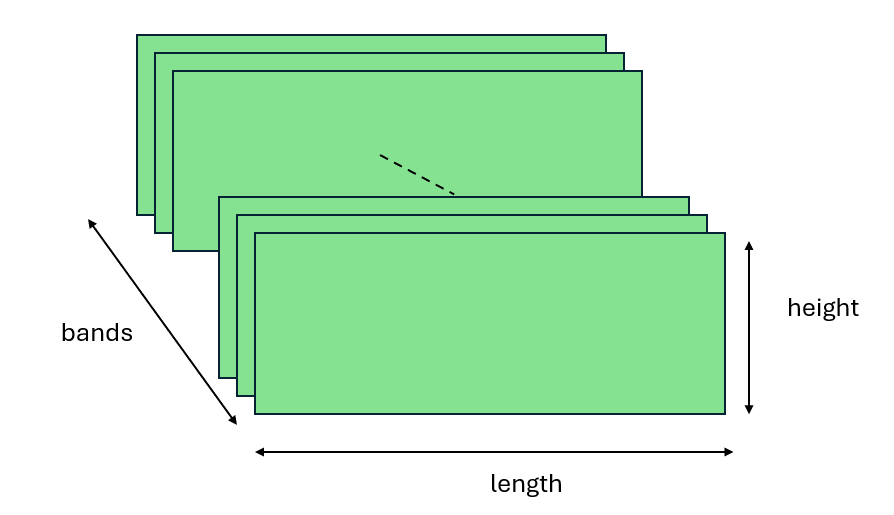

In [ ]:

gt = pd.read_excel('./groundtruth.xlsx')  # Replace with your ground truth file path
raw_data_base_path = './raw_data'
seg_data_base_path = './seg_data'
raw_files = glob.glob(os.path.join(raw_data_base_path, '*.npz'))
seg_files = glob.glob(os.path.join(seg_data_base_path, '*.npz'))
file_names = gt['file_name'].tolist()

example_file = file_names[0] + '.npz'
raw_data = np.load(os.path.join(raw_data_base_path, example_file))
seg_data = np.load(os.path.join(seg_data_base_path, example_file))

# shape: (height, length, bands) = (224, 1111, 364)
raw_img = raw_data['arr_0']

# shape: (height, length) = (224, 1111)
leaf_mask = seg_data['leaf_mask']
vein_mask = seg_data['vein_mask']
mrib_mask = seg_data['mrib_mask']
meso_mask = seg_data['meso_mask']
leaf_edge_mask = seg_data['leaf_edge_mask']
leaf_tip_mask = seg_data['leaf_tip_mask']
cln_leaf_mask = seg_data['cln_leaf_mask']

print(f'Raw image shape: {raw_img.shape}')
for key in seg_data.keys():
    print(f'{key} shape: {seg_data[key].shape}')


Raw image shape: (224, 1111, 364)
leaf_mask shape: (224, 1111)
vein_mask shape: (224, 1111)
mrib_mask shape: (224, 1111)
meso_mask shape: (224, 1111)
leaf_edge_mask shape: (224, 1111)
leaf_tip_mask shape: (224, 1111)
cln_leaf_mask shape: (224, 1111)


### Visualize the mask

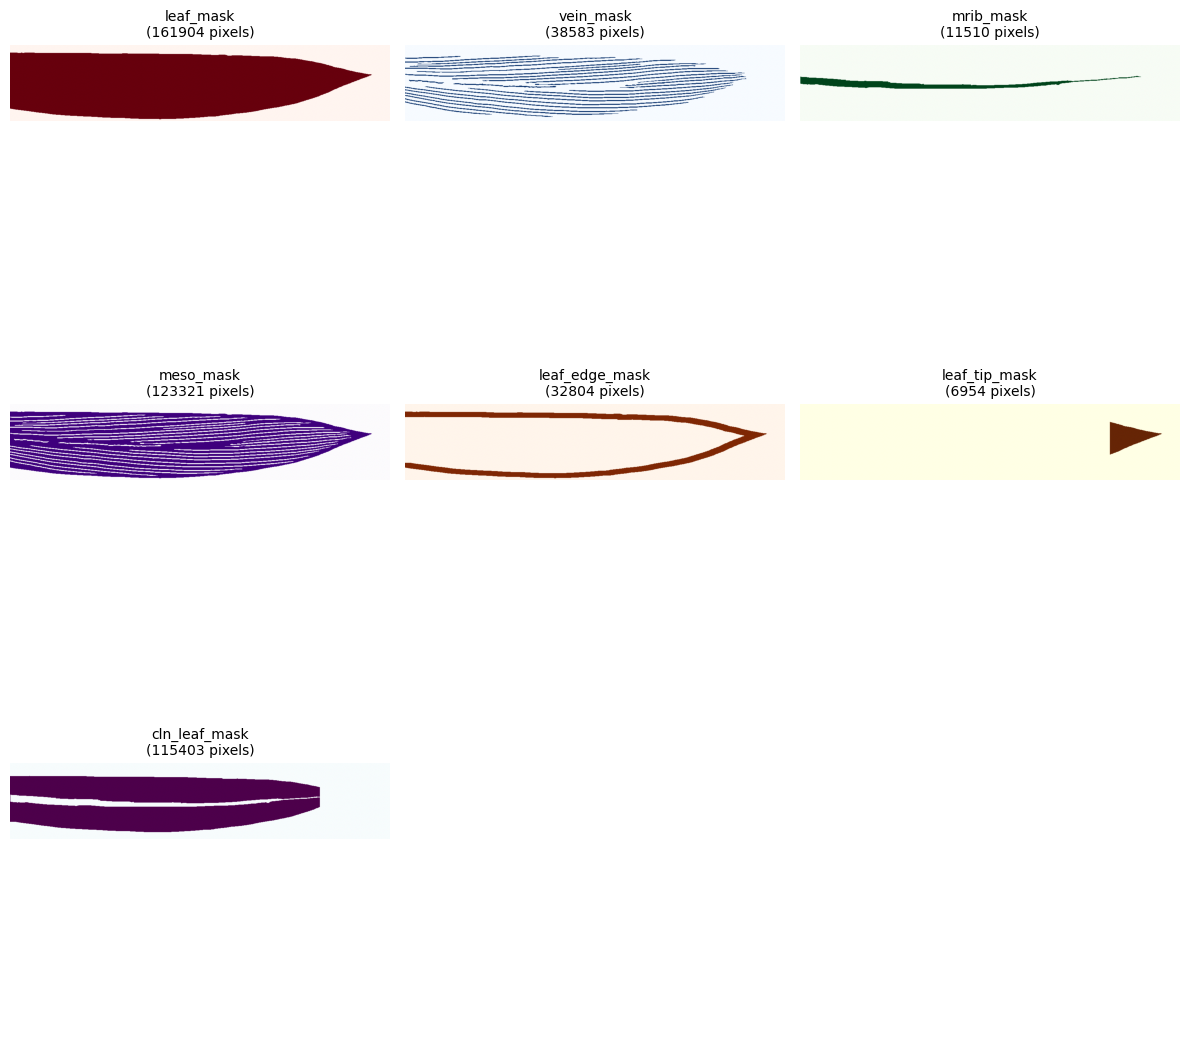

In [ ]:
# Visualize ALL segmentation masks
def visualize_all_masks(raw_img, seg_data):
    """
    Visualize all segmentation masks - simplified version
    """
    # Get all masks
    mask_names = list(seg_data.keys())
    n_masks = len(mask_names)
    
    # Create subplot layout - display only masks without the original image
    cols = 3
    rows = (n_masks + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(12, 4*rows))
    if rows == 1:
        axes = [axes] if cols == 1 else axes
    else:
        axes = axes.flatten()
    
    # Display each mask
    colors = ['Reds', 'Blues', 'Greens', 'Purples', 'Oranges', 'YlOrBr', 'BuPu']
    
    for i, mask_name in enumerate(mask_names):
        mask = seg_data[mask_name]
        pixel_count = np.sum(mask)
        
        # Display mask with different color maps
        color = colors[i % len(colors)]
        axes[i].imshow(mask, cmap=color)
        axes[i].set_title(f'{mask_name}\n({pixel_count} pixels)', fontsize=10)
        axes[i].axis('off')
    
    # Hide unused subplots
    for i in range(n_masks, len(axes)):
        axes[i].axis('off')
    
    plt.tight_layout()
    plt.show()

# Call the visualization function
visualize_all_masks(raw_img, seg_data)


Take SINGLE matrix from NPZ file

In [12]:
import numpy as np

# # Load the npz file
# data = np.load("your_file.npz")

# Get one matrix, e.g. the 'leaf_mask' array
leaf_mask = seg_data["leaf_mask"]

# Check its shape and type
print(leaf_mask.shape)

(224, 1111)


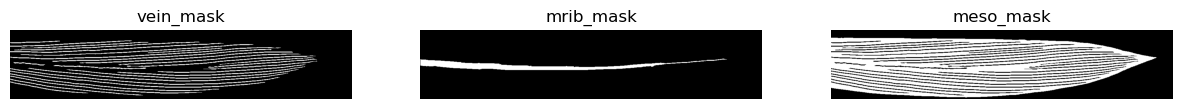

In [10]:
# Visualize CERTAIN segmentation masks
keys_to_show = ["vein_mask", "mrib_mask", "meso_mask"]

fig, axes = plt.subplots(1, len(keys_to_show), figsize=(15, 4))
for ax, k in zip(axes, keys_to_show):
    ax.imshow(seg_data[k], cmap="gray")
    ax.set_title(k)
    ax.axis("off")
plt.show()


### Calculate and display NDVI and OCAR indices

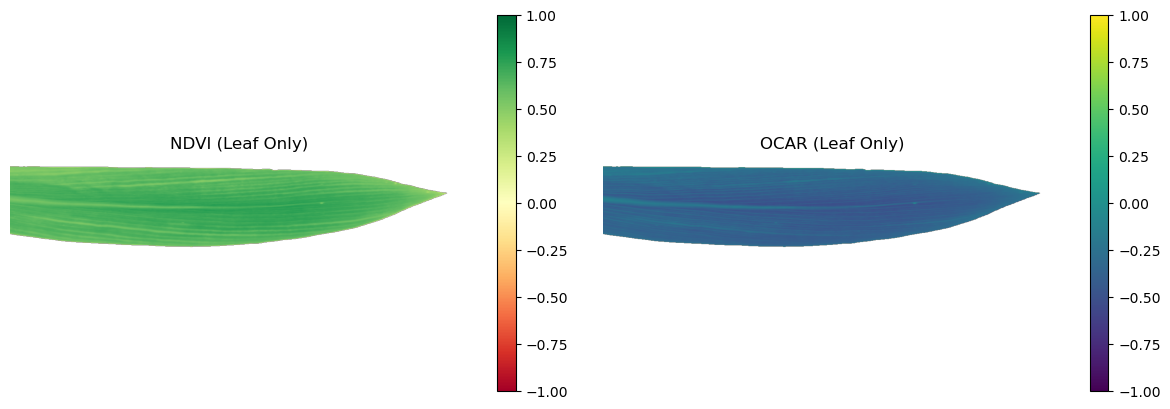

=== Vegetation Index Summary ===
NDVI (Leaf Area): 0.648 ± 0.070
OCAR (Leaf Area): -0.361 ± 0.082


In [ ]:


# 0. wavelength mapping

pst2wv_coe = [1.3330, 461.7562]
def band_to_wavelength(band_index):
    return (band_index + 50) * pst2wv_coe[0] + pst2wv_coe[1]

# 1. define necessary variables and functions
wavelengths = np.array([band_to_wavelength(i) for i in range(364)])

# Find the band indices corresponding to red and near-infrared wavelengths
red_band_idx = min(range(len(wavelengths)), key=lambda i: abs(wavelengths[i] - 670))
nir_band_idx = min(range(len(wavelengths)), key=lambda i: abs(wavelengths[i] - 800))

def calculate_ndvi(hyperspectral_img, red_idx, nir_idx):
    """
    Calculate the Normalized Difference Vegetation Index (NDVI)
    NDVI = (NIR - RED) / (NIR + RED)
    """
    red_band = hyperspectral_img[:, :, red_idx].astype(np.float64)
    nir_band = hyperspectral_img[:, :, nir_idx].astype(np.float64)
    epsilon = 1e-10
    ndvi = (nir_band - red_band) / (nir_band + red_band + epsilon)
    return ndvi

def calculate_ocar(hyperspectral_img, wavelengths):
    """
    Calculate the OCAR index
    OCAR = (Red Edge - Green) / (Red Edge + Green)
    Red Edge ≈ 730 nm, Green ≈ 550 nm
    """
    green_target = 550
    red_edge_target = 730
    
    green_band_idx = min(range(len(wavelengths)), key=lambda i: abs(wavelengths[i] - green_target))
    red_edge_band_idx = min(range(len(wavelengths)), key=lambda i: abs(wavelengths[i] - red_edge_target))
    
    green_band = hyperspectral_img[:, :, green_band_idx].astype(np.float64)
    red_edge_band = hyperspectral_img[:, :, red_edge_band_idx].astype(np.float64)
    
    epsilon = 1e-10
    ocar = (red_edge_band - green_band) / (red_edge_band + green_band + epsilon)
    
    return ocar

# Compute NDVI and OCAR
ndvi = calculate_ndvi(raw_img, red_band_idx, nir_band_idx)
ocar = calculate_ocar(raw_img, wavelengths)

# Simplified visualization — display NDVI and OCAR only within the leaf mask
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Masked NDVI (leaf region only)
ndvi_masked = np.where(leaf_mask, ndvi, np.nan)
im1 = axes[0].imshow(ndvi_masked, cmap='RdYlGn', vmin=-1, vmax=1)
axes[0].set_title('NDVI (Leaf Only)')
axes[0].axis('off')
plt.colorbar(im1, ax=axes[0], shrink=0.8)

# Masked OCAR (leaf region only)
ocar_masked = np.where(leaf_mask, ocar, np.nan)
im2 = axes[1].imshow(ocar_masked, cmap='viridis', vmin=-1, vmax=1)
axes[1].set_title('OCAR (Leaf Only)')
axes[1].axis('off')
plt.colorbar(im2, ax=axes[1], shrink=0.8)

plt.tight_layout()
plt.show()

# Print summary statistics
print("=== Vegetation Index Summary ===")
print(f"NDVI (Leaf Area): {np.nanmean(ndvi_masked):.3f} ± {np.nanstd(ndvi_masked):.3f}")
print(f"OCAR (Leaf Area): {np.nanmean(ocar_masked):.3f} ± {np.nanstd(ocar_masked):.3f}")


### Generate feature table using segmentation masks and NDVI


In [ ]:

def extract_features_from_masks_and_ndvi(raw_img, seg_data, ndvi, file_name):
    """
    Extract NDVI-based features from different mask regions
    """
    features = {'file_name': file_name}
    
    # Get all masks
    mask_names = list(seg_data.keys())
    
    for mask_name in mask_names:
        mask = seg_data[mask_name]
        
        # Extract NDVI values within the current mask region
        ndvi_masked = ndvi[mask > 0]
        
        if len(ndvi_masked) > 0:
            # NDVI statistical features
            features[f'{mask_name}_ndvi_mean'] = np.mean(ndvi_masked)
            features[f'{mask_name}_ndvi_std'] = np.std(ndvi_masked)
            features[f'{mask_name}_ndvi_min'] = np.min(ndvi_masked)
            features[f'{mask_name}_ndvi_max'] = np.max(ndvi_masked)
            features[f'{mask_name}_ndvi_median'] = np.median(ndvi_masked)
            
            # Pixel count and percentage
            features[f'{mask_name}_pixel_count'] = np.sum(mask)
            features[f'{mask_name}_pixel_percentage'] = (np.sum(mask) / mask.size) * 100
        else:
            # If mask is empty, fill with NaN or zeros
            for stat in ['mean', 'std', 'min', 'max', 'median']:
                features[f'{mask_name}_ndvi_{stat}'] = np.nan
            features[f'{mask_name}_pixel_count'] = 0
            features[f'{mask_name}_pixel_percentage'] = 0.0
    
    return features


def process_all_files_and_create_feature_table():
    """
    Process all files and create a complete feature table
    """
    # Read ground truth data
    gt = pd.read_excel('./groundtruth.xlsx')
    
    # Initialize feature list
    all_features = []
    
    # Use predefined wavelengths
    wavelengths = np.array([band_to_wavelength(i) for i in range(364)])
    
    # Find the indices of red and near-infrared bands
    red_band_idx = min(range(len(wavelengths)), key=lambda i: abs(wavelengths[i] - 670))
    nir_band_idx = min(range(len(wavelengths)), key=lambda i: abs(wavelengths[i] - 800))
    
    # Process each file
    for file_name in gt['file_name'].tolist():
        try:
            # Load hyperspectral data and segmentation masks
            raw_data = np.load(os.path.join('./raw_data', f'{file_name}.npz'))
            seg_data = np.load(os.path.join('./seg_data', f'{file_name}.npz'))
            
            raw_img = raw_data['arr_0']
            
            # Compute NDVI
            ndvi = calculate_ndvi(raw_img, red_band_idx, nir_band_idx)
            
            # Extract features from each mask region
            features = extract_features_from_masks_and_ndvi(raw_img, seg_data, ndvi, file_name)
            all_features.append(features)
            
        except Exception as e:
            print(f"Error processing {file_name}: {e}")
            continue
    
    # Create a DataFrame containing all features
    features_df = pd.DataFrame(all_features)
    
    # Merge with ground truth
    final_df = pd.merge(gt, features_df, on='file_name', how='left')
    
    return final_df


# Execute feature extraction
feature_table = process_all_files_and_create_feature_table()

# Save results
feature_table.to_csv('features_with_masks_and_ndvi.csv', index=False)
feature_table.to_excel('features_with_masks_and_ndvi.xlsx', index=False)

print(f"Feature table shape: {feature_table.shape}")
print("Feature table saved successfully.")


Feature table shape: (40, 53)
Feature table saved successfully.


### Load data and build a PLS model with 5-fold cross-validation


🔹 Steps:

Split the dataset into 5 equal parts (called folds).

Use 4 folds for training and 1 fold for testing.

Repeat this process 5 times, each time changing which fold is used for testing.

Compute performance (e.g., accuracy, RMSE) for each fold.

Take the average of the 5 scores → this is the final result.

In [13]:

from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Load feature data
# feature_table = pd.read_excel('features_with_masks_and_ndvi.xlsx')
feature_table = pd.read_csv('features_with_masks_and_ndvi.csv')

# Prepare data
X = feature_table.drop(columns=['file_name', 'N', 'genotype', 'treatment'])  # Feature columns
y = feature_table['N']

# Remove rows containing NaN values
mask = ~(X.isnull().any(axis=1) | y.isnull())
X = X[mask]
y = y[mask]

# 5-fold cross-validation setup
kf = KFold(n_splits=5, shuffle=True, random_state=42)
n_components = 10  # Number of PLS components

predictions = []
actuals = []
r2_scores = []
rmse_scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X)):
    # Split the data
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
    
    # Build the PLS model
    pls = PLSRegression(n_components=n_components)
    pls.fit(X_train, y_train)
    
    # Make predictions
    y_pred = pls.predict(X_val).flatten()
    
    # Evaluate model performance
    r2 = r2_score(y_val, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    
    predictions.extend(y_pred)
    actuals.extend(y_val)
    r2_scores.append(r2)
    rmse_scores.append(rmse)
    
    print(f"Fold {fold+1}: R² = {r2:.3f}, RMSE = {rmse:.3f}")

# Overall performance
overall_r2 = r2_score(actuals, predictions)
overall_rmse = np.sqrt(mean_squared_error(actuals, predictions))

print(f"\nOverall Results:")
print(f"R² = {overall_r2:.3f}")
print(f"RMSE = {overall_rmse:.3f}")
print(f"Average R² = {np.mean(r2_scores):.3f} ± {np.std(r2_scores):.3f}")
print(f"Average RMSE = {np.mean(rmse_scores):.3f} ± {np.std(rmse_scores):.3f}")

# Save prediction results
results_df = pd.DataFrame({
    'Actual_N': actuals,
    'Predicted_N': predictions
})


Fold 1: R² = 0.470, RMSE = 0.368
Fold 2: R² = 0.499, RMSE = 0.380
Fold 3: R² = 0.464, RMSE = 0.369
Fold 4: R² = 0.817, RMSE = 0.200
Fold 5: R² = 0.618, RMSE = 0.307

Overall Results:
R² = 0.590
RMSE = 0.332
Average R² = 0.574 ± 0.134
Average RMSE = 0.325 ± 0.067


### Visualize PLS prediction results

Plotting treatment: N1, n=20
Plotting treatment: N2, n=20


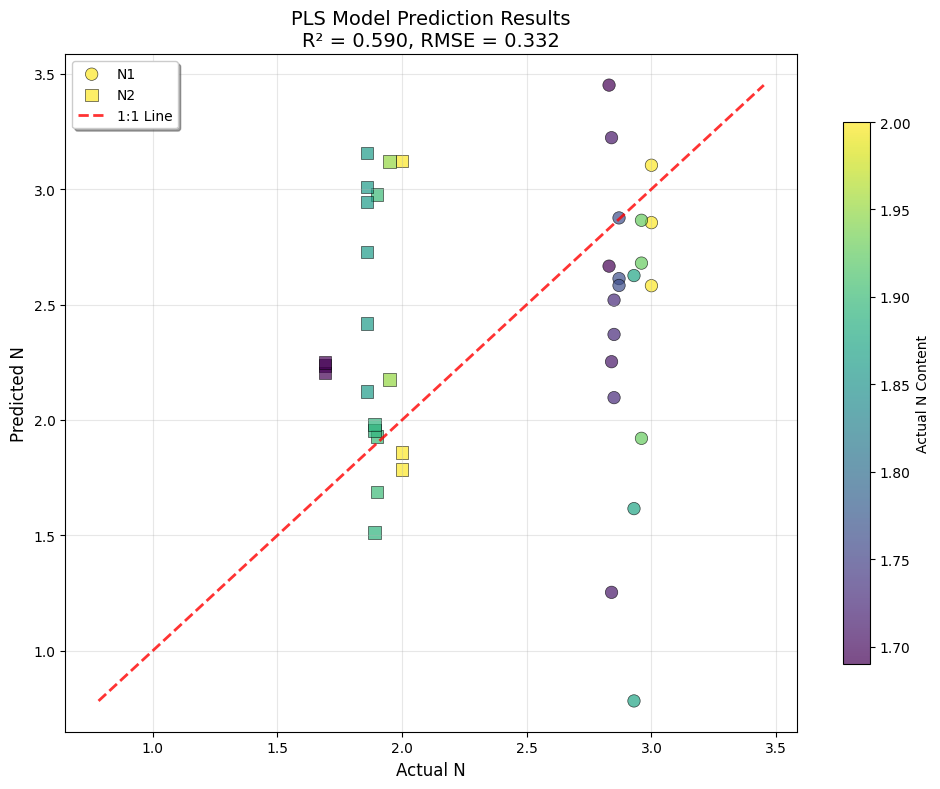


=== Treatment Statistics ===
N1: R² = -164.370, RMSE = 0.784, n = 20
N2: R² = -61.453, RMSE = 0.717, n = 20


In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# Retrieve corresponding treatment information
file_names_used = feature_table[mask]['file_name'].values
treatments = feature_table[mask]['treatment'].values
actual_n = feature_table[mask]['N'].values   # Use true N values from feature_table
predicted_n = np.array(predictions)

# Create figure
fig, ax = plt.subplots(figsize=(10, 8))

# Define marker styles for different treatments
treatment_markers = {
    'N1': 'o',      # Circle
    'N2': 's',      # Square
}

# Get unique treatment types
unique_treatments = np.unique(treatments)

# Plot scatter points for each treatment
for treatment in unique_treatments:
    mask_treatment = treatments == treatment
    print(f"Plotting treatment: {treatment}, n={np.sum(mask_treatment)}")
    
    # Use actual N values for color intensity
    scatter = ax.scatter(
        actual_n[mask_treatment],
        predicted_n[mask_treatment],
        c=actual_n[mask_treatment],
        marker=treatment_markers.get(treatment),
        s=80,
        alpha=0.7,
        cmap='viridis',
        label=treatment,
        edgecolors='black',
        linewidth=0.5
    )

# Add 1:1 reference line
min_val = min(actual_n.min(), predicted_n.min())
max_val = max(actual_n.max(), predicted_n.max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', alpha=0.8, linewidth=2, label='1:1 Line')

# Set axis labels and title
ax.set_xlabel('Actual N', fontsize=12)
ax.set_ylabel('Predicted N', fontsize=12)
ax.set_title(f'PLS Model Prediction Results\nR² = {overall_r2:.3f}, RMSE = {overall_rmse:.3f}', fontsize=14)

# Add legend
ax.legend(loc='upper left', frameon=True, fancybox=True, shadow=True)

# Add colorbar
cbar = plt.colorbar(scatter, ax=ax, shrink=0.8)
cbar.set_label('Actual N Content', fontsize=10)

# Enable grid
ax.grid(True, alpha=0.3)

# Adjust layout
plt.tight_layout()
plt.show()


# Print per-treatment statistics
print("\n=== Treatment Statistics ===")
for treatment in unique_treatments:
    mask_treatment = treatments == treatment
    treatment_r2 = r2_score(actual_n[mask_treatment], predicted_n[mask_treatment])
    treatment_rmse = np.sqrt(mean_squared_error(actual_n[mask_treatment], predicted_n[mask_treatment]))
    print(f"{treatment}: R² = {treatment_r2:.3f}, RMSE = {treatment_rmse:.3f}, n = {np.sum(mask_treatment)}")
